In [4]:
import json
import pandas as pd
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load original JSON dataset
file_path = "dataset/inflation+research+abstracts+classification/classified_abstracts.json"

with open(file_path, "r", encoding="utf-8") as file:
    data = json.load(file)

df = pd.DataFrame(data)[["Abstract", "Label"]]
df = df.dropna(subset=["Abstract", "Label"]).drop_duplicates()

# Clean abstract text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["Abstract"] = df["Abstract"].apply(clean_text)
df = df[df["Abstract"] != ""]
df["Label"] = df["Label"].astype(int)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    df["Abstract"],
    df["Label"],
    test_size=0.2,
    random_state=42,
    stratify=df["Label"]
)

# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(max_features=5000, stop_words="english")
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train Logistic Regression classifier
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

# Predict and evaluate
y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.84

Confusion Matrix:
[[178   0]
 [ 36  11]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91       178
           1       1.00      0.23      0.38        47

    accuracy                           0.84       225
   macro avg       0.92      0.62      0.64       225
weighted avg       0.87      0.84      0.80       225



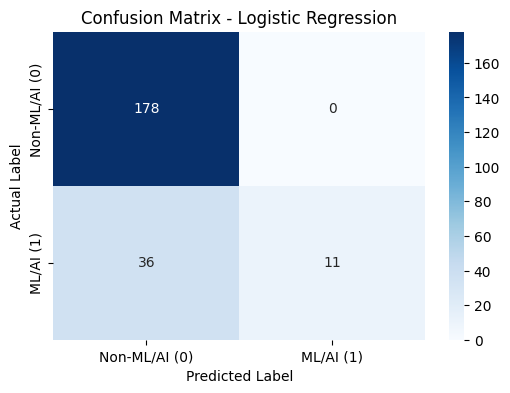

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-ML/AI (0)", "ML/AI (1)"],
    yticklabels=["Non-ML/AI (0)", "ML/AI (1)"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [6]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Model: Logistic Regression with TF-IDF")
print("--------------------------------------")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred, zero_division=0):.4f}")

Model: Logistic Regression with TF-IDF
--------------------------------------
Accuracy : 0.8400
Precision: 1.0000
Recall   : 0.2340
F1-Score : 0.3793


## Result
The Inflation Research Abstracts Classification dataset was classified using a Logistic Regression model. The original JSON dataset was loaded, cleaned, and divided into training and testing sets using an 80:20 ratio. TF-IDF was used to convert the textual abstracts into numerical features. The model was trained on the training data and evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

## Conclusion
The Logistic Regression model successfully performed binary text classification to identify research abstracts related to machine learning and artificial intelligence methodologies. The model's performance was evaluated on unseen test data. This experiment demonstrates the use of text preprocessing, TF-IDF feature extraction, and supervised machine learning for scientific abstract classification.